# v2 새 핀 클래스 PTP 단축경로 검증

## 검증 가설
v2의 새 핀 4개 (엘도스 수출용 / 이튼큐 / 동화덴스톨 / 투스딘골드) 중 3개가 클래스명에 "PTP" 표기.
가설: 합성 v2 또는 K-code 학습 풀에서 PTP 형태 알약이 단축경로로 학습됨.

## 검증 항목
1. 검증 클래스 10개 (baseline 핀 6 + v2 새 핀 4) K-code 학습 풀 외형 확인 — PTP 형태 비율
2. K-code 학습 풀 전체에서 "/PTP" 표기 클래스 비율
3. Test 33장에서 PTP 등장 GT 명단 + verdict
4. 합성 v2 알약 풀 (crops_cache) 의 PTP 알약 비율 (가능 시)

## 데이터 소스
- D:\pill_detection\data\team_preprocessed\clean_df.csv (K-code 학습 ann 39,864)
- D:\pill_detection\data\dataset_yolo\images\{train,val} (K-code 이미지)
- 분석 노트북 06 의 결과 (test_classes, top1_v 등 — 본 노트북에서 다시 매칭 안 함, 이미 구한 명단 활용)

## 셋업 + 검증 클래스 10개

In [1]:
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

ROOT = Path(r"D:\pill_detection")
KCODE_TRAIN = ROOT / "data" / "dataset_yolo" / "images" / "train"
KCODE_VAL   = ROOT / "data" / "dataset_yolo" / "images" / "val"
CLEAN_DF    = ROOT / "data" / "team_preprocessed" / "clean_df.csv"

# 데이터 존재 확인
print("=" * 70)
print("데이터 소스 존재 확인")
print("=" * 70)
for label, p in [
    ("K-code train", KCODE_TRAIN),
    ("K-code val  ", KCODE_VAL),
    ("clean_df    ", CLEAN_DF),
]:
    if p.is_dir():
        print(f"  {label}: {p.exists()} ({len(list(p.glob('*.png')))} png)")
    else:
        print(f"  {label}: {p.exists()} ({p.stat().st_size / 1e6:.1f} MB)" if p.exists() else f"  {label}: 없음")

# clean_df 로드
cdf = pd.read_csv(CLEAN_DF)
print(f"\nclean_df: {len(cdf)} rows / 컬럼: {list(cdf.columns)}")
print(cdf.head(3))

# train/val 파일 set
train_files = {f.name for f in KCODE_TRAIN.glob('*.png')}
val_files   = {f.name for f in KCODE_VAL.glob('*.png')}
all_existing = train_files | val_files
cdf_exist = cdf[cdf['file_name'].isin(all_existing)].copy()
print(f"\ntrain+val 실제 존재: {len(all_existing)} 파일")
print(f"clean_df 중 실제 존재 ann: {len(cdf_exist)}")

def find_path(fname):
    if fname in train_files: return KCODE_TRAIN / fname
    if fname in val_files:   return KCODE_VAL / fname
    return None

def imread_kr(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)

def crop_pill_roi(path, bbox_xywh, pad=10):
    """clean_df의 bbox는 xywh 형식"""
    img = imread_kr(path)
    if img is None: return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    x, y, w, h = [int(v) for v in bbox_xywh]
    H, W = img.shape[:2]
    x1 = max(0, x - pad); y1 = max(0, y - pad)
    x2 = min(W, x + w + pad); y2 = min(H, y + h + pad)
    return img[y1:y2, x1:x2]


# 검증 클래스 10개 (06 노트북 결과)
baseline_pin = [
    '엘스테인캡슐(에르도스테인)',
    '이가탄에프캡슐 150mg/PTP',
    '알바스테인캡슐(에르도스테인)',
    '람노스캡슐500mg/병',
    '메가파워정 90mg/병',
    '카발린캡슐 25mg',
]
v2_new_pin = [
    '엘도스캡슐(에르도스테인)(수출용)',
    '이튼큐정 35mg/PTP',
    '동화덴스톨캡슐 150mg/PTP',
    '투스딘골드캡슐 150mg/PTP',
]
audit_classes = baseline_pin + v2_new_pin

# clean_df 에 있는지 확인 + 학습 ann 카운트
print("\n" + "=" * 90)
print("검증 클래스 10개 — K-code 학습 풀 등장 여부")
print("=" * 90)
print(f"{'group':10s} {'class':45s} {'train_ann':>9s} {'val_ann':>7s} {'name_PTP':>9s}")
print("-" * 90)
class_train_count = cdf_exist[cdf_exist['file_name'].isin(train_files)]['dl_name'].value_counts().to_dict()
class_val_count   = cdf_exist[cdf_exist['file_name'].isin(val_files)]['dl_name'].value_counts().to_dict()

audit_summary = []
for label, classes in [('baseline_pin', baseline_pin), ('v2_new_pin', v2_new_pin)]:
    for c in classes:
        ta = class_train_count.get(c, 0)
        va = class_val_count.get(c, 0)
        name_ptp = '✓' if 'PTP' in c else '-'
        print(f"  {label:10s} {c[:43]:45s} {ta:9d} {va:7d} {name_ptp:>9s}")
        audit_summary.append({
            'group': label, 'class': c,
            'train_ann': ta, 'val_ann': va,
            'name_has_PTP': 'PTP' in c,
        })
audit_df = pd.DataFrame(audit_summary)

# 클래스명 PTP 비율 1차 통계
print("\n" + "=" * 90)
print("검증 클래스 10개 — 클래스명 'PTP' 표기 비율")
print("=" * 90)
for label in ['baseline_pin', 'v2_new_pin']:
    sub = audit_df[audit_df['group'] == label]
    n = len(sub); n_ptp = sub['name_has_PTP'].sum()
    print(f"  {label}: {n_ptp}/{n} ({n_ptp/n*100:.0f}%)")

데이터 소스 존재 확인
  K-code train: True (8302 png)
  K-code val  : True (2090 png)
  clean_df    : True (29.5 MB)

clean_df: 39864 rows / 컬럼: ['file_name', 'image_id', 'width', 'height', 'category_id', 'dl_name', 'dl_name_en', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'area', 'color_class1', 'color_class2', 'drug_shape', 'print_front', 'print_back', 'form_code_name', 'di_etc_otc_code', 'camera_la', 'leng_long', 'leng_short', 'thick', 'class_idx', 'class_name', 'bbox_cx', 'bbox_cy', 'bbox_cx_n', 'bbox_cy_n', 'bbox_w_n', 'bbox_h_n', 'back_color', 'di_class_no', 'dl_company', 'dl_idx', 'dl_mapping_code', 'dl_material', 'drug_dir', 'image_exists', 'json_path', 'light_color', 'set_id', 'source', 'category_id_merged', 'final_class_idx_merged']
                                           file_name  image_id  width  height  \
0  K-001900-016548-019607-029451_0_2_0_2_70_000_2...        34    976    1280   
1  K-001900-016548-019607-029451_0_2_0_2_75_000_2...        35    976    1280   
2  K-001900-01654

C:\Users\tran6\AppData\Local\Temp\ipykernel_12996\2892521319.py:31: DtypeWarning: Columns (38) have mixed types. Specify dtype option on import or set low_memory=False.
  cdf = pd.read_csv(CLEAN_DF)


## 검증 1 — 검증 클래스 10개 K-code 학습 풀 외형

각 클래스마다 K-code 학습 이미지 3장씩 ROI 추출. 시각으로:
- baseline 핀 6개 — 어떻게 생겼나 (PTP 형태 vs 단일 알약)
- v2 새 핀 4개 — 정말 PTP 형태가 우세한가
- 두 그룹 외형 차이가 명확한지 (단축경로 후보 패턴 시각 검증)

ROI 자르기: clean_df bbox_xywh 기준, 패딩 10px.

저장: D:\pill_detection\analysis\figures_v2_compare\07_pin_class_pool.png


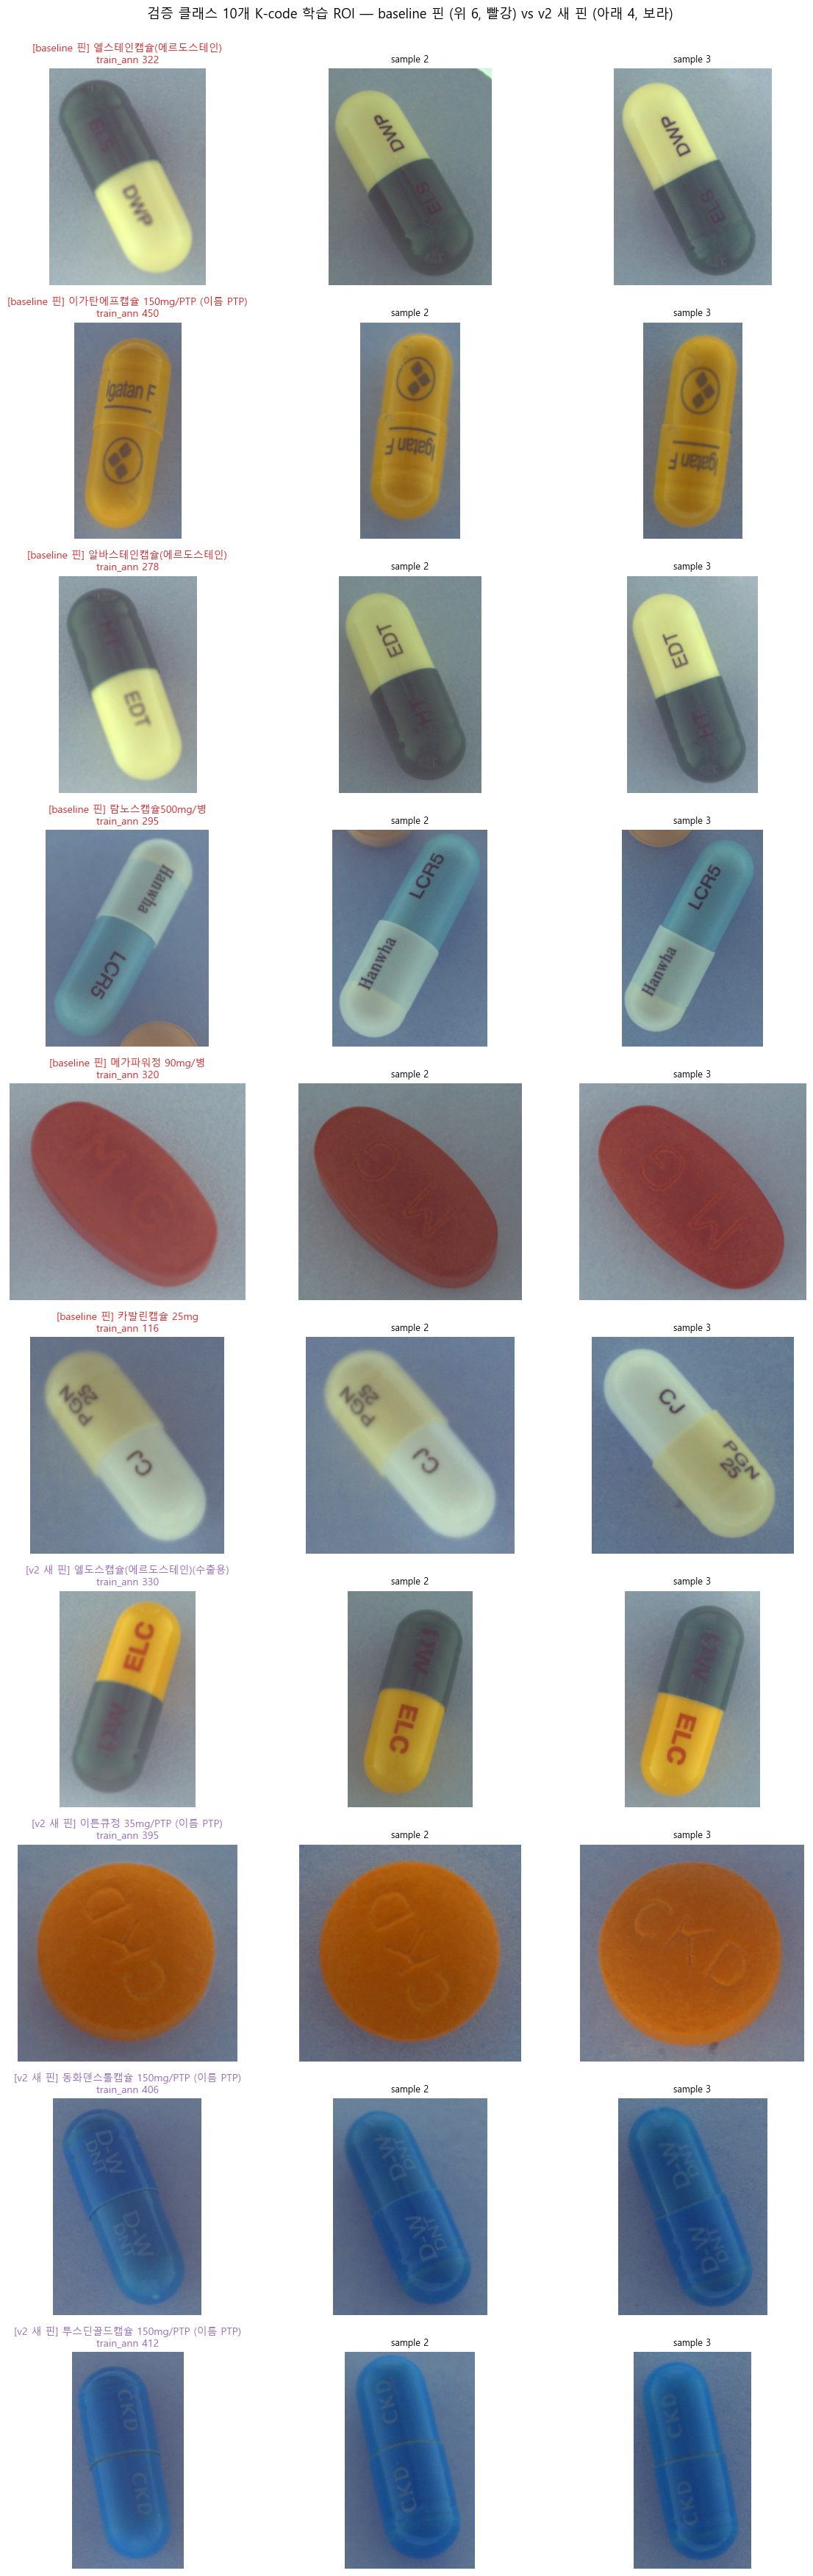

In [2]:
def get_n_samples_for_dl(dl_name, n=3):
    """한 dl_name 에 대해 다른 파일 n개 샘플 (train 우선)"""
    sub = cdf_exist[cdf_exist['dl_name'] == dl_name]
    sub = sub.drop_duplicates(subset='file_name')
    # train 파일 우선
    sub_train = sub[sub['file_name'].isin(train_files)].head(n)
    if len(sub_train) >= n:
        return sub_train
    sub_val = sub[sub['file_name'].isin(val_files)].head(n - len(sub_train))
    return pd.concat([sub_train, sub_val])


n_classes = len(audit_classes)
n_samples_per = 3
fig, axes = plt.subplots(n_classes, n_samples_per,
                         figsize=(n_samples_per * 4, n_classes * 3.5))

for i, c in enumerate(audit_classes):
    is_baseline_pin = c in baseline_pin
    group_label = '[baseline 핀]' if is_baseline_pin else '[v2 새 핀]'
    color = 'tab:red' if is_baseline_pin else 'tab:purple'
    ta = class_train_count.get(c, 0)
    name_ptp_mark = ' (이름 PTP)' if 'PTP' in c else ''
    
    samples = get_n_samples_for_dl(c, n_samples_per)
    
    for k, (_, s) in enumerate(samples.iterrows()):
        ax = axes[i, k]
        path = find_path(s['file_name'])
        if path is None:
            ax.text(0.5, 0.5, '경로 없음', ha='center', va='center',
                    transform=ax.transAxes)
            ax.axis('off'); continue
        roi = crop_pill_roi(path, (s['bbox_x'], s['bbox_y'], s['bbox_w'], s['bbox_h']))
        if roi is not None:
            ax.imshow(roi)
        if k == 0:
            ax.set_title(f"{group_label} {c[:24]}{name_ptp_mark}\ntrain_ann {ta}",
                         fontsize=10, color=color)
        else:
            ax.set_title(f"sample {k+1}", fontsize=9)
        ax.axis('off')

plt.suptitle("검증 클래스 10개 K-code 학습 ROI — baseline 핀 (위 6, 빨강) vs v2 새 핀 (아래 4, 보라)",
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures_v2_compare" / "07_pin_class_pool.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

## 검증 가설 정정 — PTP X / 캡슐 형태 단축경로

시각 결과: 클래스명 "PTP" 표기와 학습 이미지 형태 무관.
새 가설: 캡슐 형태가 단축경로. 검증 클래스 10개 중 8개(80%)가 캡슐.

검증 항목 (clean_df 의 drug_shape 컬럼 활용):
- K-code 학습 풀 118 클래스의 drug_shape 분포 (base rate)
- Test 33장 47 GT 중 캡슐 GT 명단 + 두 모델 verdict
- v2 1순위 예측 145건 중 캡슐 호출 비율 vs base rate
- 정량적 편향 (chi-square 또는 단순 비율 차이)

In [3]:
# 1) clean_df 의 drug_shape 컬럼 분포
print("=" * 75)
print("clean_df drug_shape 컬럼 unique values")
print("=" * 75)
print(cdf_exist['drug_shape'].value_counts(dropna=False))

# 2) 클래스별 dominant drug_shape (한 클래스 내 ann이 다 같은 shape인지 확인)
print("\n" + "=" * 75)
print("클래스별 drug_shape 분산 (검증 클래스 10개)")
print("=" * 75)
for c in audit_classes:
    sub = cdf_exist[cdf_exist['dl_name'] == c]
    shapes = sub['drug_shape'].value_counts(dropna=False).to_dict()
    print(f"  {c[:35]:35s} {shapes}")

# 3) 각 클래스의 dominant shape 추출
class_shape = cdf_exist.groupby('dl_name')['drug_shape'].agg(
    lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else None
).to_dict()

# 4) K-code 학습 풀 118 클래스의 shape 분포 (base rate)
print("\n" + "=" * 75)
print("K-code 학습 풀 118 클래스의 dominant drug_shape (base rate)")
print("=" * 75)
shape_class_count = pd.Series(class_shape).value_counts(dropna=False)
total = len(class_shape)
for s, n in shape_class_count.items():
    print(f"  {str(s):20s} {n:3d}개 ({n/total*100:5.1f}%)")

# 5) 검증 클래스 10개 dominant shape
print("\n" + "=" * 75)
print("검증 클래스 10개 dominant shape")
print("=" * 75)
audit_shapes = []
for label, classes in [('baseline_pin', baseline_pin), ('v2_new_pin', v2_new_pin)]:
    for c in classes:
        s = class_shape.get(c)
        audit_shapes.append({'group': label, 'class': c, 'dominant_shape': s})
        print(f"  {label:12s} {c[:35]:35s} → {s}")
audit_shapes_df = pd.DataFrame(audit_shapes)

print("\n그룹별 캡슐 비율:")
for label in ['baseline_pin', 'v2_new_pin']:
    sub = audit_shapes_df[audit_shapes_df['group'] == label]
    n = len(sub); n_cap = (sub['dominant_shape'] == '캡슐').sum()
    print(f"  {label}: 캡슐 {n_cap}/{n} ({n_cap/n*100:.0f}%)")

# 6) 베이스 비율 (전체 118 클래스의 캡슐 비율)
n_capsule_all = (pd.Series(class_shape) == '캡슐').sum()
print(f"\n전체 118 클래스 base rate: 캡슐 {n_capsule_all}/118 ({n_capsule_all/118*100:.1f}%)")
print(f"\n→ 검증 클래스 10개의 캡슐 비율이 base rate보다 의미있게 높으면 캡슐 단축경로 가설 강화")

clean_df drug_shape 컬럼 unique values
drug_shape
원형     13844
장방형    12222
타원형    11197
NaN      882
기타       447
삼각형      441
팔각형      424
육각형      407
Name: count, dtype: int64

클래스별 drug_shape 분산 (검증 클래스 10개)
  엘스테인캡슐(에르도스테인)                      {'장방형': 383}
  이가탄에프캡슐 150mg/PTP                   {'장방형': 515}
  알바스테인캡슐(에르도스테인)                     {'장방형': 373}
  람노스캡슐500mg/병                        {'장방형': 353}
  메가파워정 90mg/병                        {'타원형': 426}
  카발린캡슐 25mg                          {'장방형': 146}
  엘도스캡슐(에르도스테인)(수출용)                  {'장방형': 437}
  이튼큐정 35mg/PTP                       {'원형': 513}
  동화덴스톨캡슐 150mg/PTP                   {'장방형': 522}
  투스딘골드캡슐 150mg/PTP                   {'장방형': 525}

K-code 학습 풀 118 클래스의 dominant drug_shape (base rate)
  원형                    40개 ( 33.9%)
  장방형                   37개 ( 31.4%)
  타원형                   35개 ( 29.7%)
  기타                     2개 (  1.7%)
  None                   1개 (  0.8%)
  삼각형                    1개 (  0.8%)
  팔각

## 검증 가설 정정 — drug_shape "장방형" 단축경로

drug_shape 컬럼에 "캡슐" 라벨 없음. 약학 분류상 캡슐도 "장방형".
시각으로 본 캡슐 패턴 = drug_shape 장방형. 정정된 정량:
- 검증 10개 중 장방형 8개 (80%) vs base rate 31.4% = 2.55배 편향

검증 항목:
- Test 33장 47 GT의 drug_shape 분포 + verdict
- v2 1순위 예측 (매칭 + FP 합산 145건) 의 drug_shape 분포 vs base rate
- "Test에 적은 형태를 학습 풀 인기 형태로 흘려보냄" 패턴 정량 측정

Test GT 47개의 dl_name 분포
장방형     20
타원형     12
원형      11
None     2
삼각형      1
팔각형      1
Name: count, dtype: int64

Test GT 47개 중 장방형: 20/47 (42.6%)

Test unique 31 클래스 shape:
장방형     13
타원형      9
원형       6
삼각형      1
None     1
팔각형      1
Name: count, dtype: int64

baseline / v2 1순위 예측 shape 분포
shape             baseline              v2    base rate (118)
  장방형        157 ( 51.6%)      63 ( 43.4%)    37 ( 31.4%)
  원형          25 (  8.2%)      30 ( 20.7%)    40 ( 33.9%)
  타원형        103 ( 33.9%)      40 ( 27.6%)    35 ( 29.7%)
  기타          11 (  3.6%)       7 (  4.8%)     2 (  1.7%)
  삼각형          3 (  1.0%)       1 (  0.7%)     1 (  0.8%)
  팔각형          2 (  0.7%)       2 (  1.4%)     1 (  0.8%)
  육각형          0 (  0.0%)       0 (  0.0%)     1 (  0.8%)

저장: D:\pill_detection\analysis\figures_v2_compare\08_shape_distribution.png


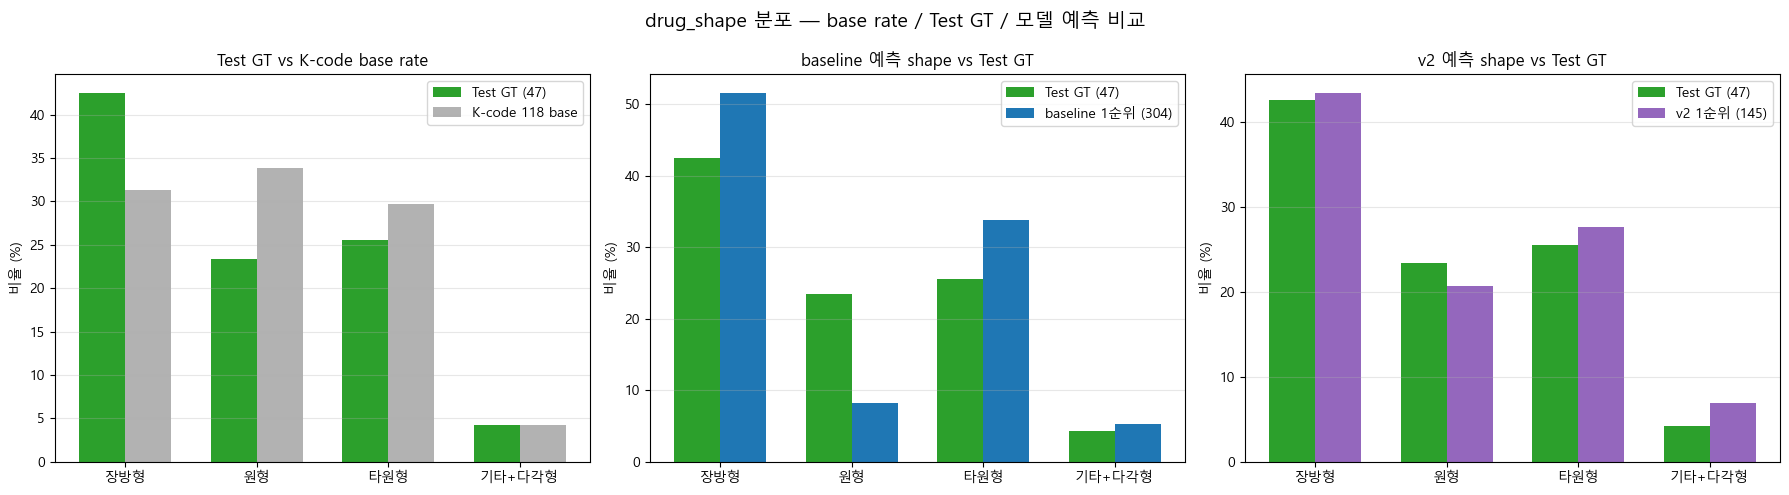

In [4]:
# 1) Test 33장 47 GT 의 drug_shape — 06 노트북의 test_classes 활용
import json
RESULTS_V2 = ROOT / "eval" / "rtmdet_tiny_synth_e14_seed100_results.json"
with open(RESULTS_V2, encoding='utf-8') as f:
    v2_results = json.load(f)

test_gt_names = []
for img_data in v2_results['results']:
    for gt in img_data['gt_bboxes']:
        test_gt_names.append(gt['dl_name'].rstrip(' \xa0\u3000'))  # NBSP 제거

print(f"Test GT 47개의 dl_name 분포")
test_gt_shapes = [class_shape.get(n) for n in test_gt_names]
test_shape_counts = pd.Series(test_gt_shapes).value_counts(dropna=False)
print(test_shape_counts)
print(f"\nTest GT 47개 중 장방형: {(pd.Series(test_gt_shapes) == '장방형').sum()}/47 "
      f"({(pd.Series(test_gt_shapes) == '장방형').sum()/47*100:.1f}%)")

# Test 등장 31개 unique 클래스 의 shape (각 클래스 1번만)
test_unique_shapes = pd.Series([class_shape.get(n) for n in set(test_gt_names)]).value_counts(dropna=False)
print(f"\nTest unique 31 클래스 shape:")
print(test_unique_shapes)


# 2) v2 1순위 예측 145건의 shape — 매칭 + FP 모두
def collect_top1_with_shape(results_obj):
    rows = []
    for img_data in results_obj['results']:
        for pred in img_data['predictions']:
            top3 = pred.get('top3_class_name', [])
            if top3:
                name = top3[0].rstrip(' \xa0\u3000')
                rows.append({
                    'dl_name': name,
                    'shape': class_shape.get(name),
                    'conf': pred.get('top3_confidence', [0])[0],
                })
    return pd.DataFrame(rows)

# baseline 도 같이
RESULTS_V1 = ROOT / "eval" / "rtmdet_tiny_synth_e15_seed100_results.json"
with open(RESULTS_V1, encoding='utf-8') as f:
    v1_results = json.load(f)

preds_v1 = collect_top1_with_shape(v1_results)
preds_v2 = collect_top1_with_shape(v2_results)

print("\n" + "=" * 75)
print("baseline / v2 1순위 예측 shape 분포")
print("=" * 75)
print(f"{'shape':10s} {'baseline':>15s} {'v2':>15s} {'base rate (118)':>18s}")
all_shapes = ['장방형', '원형', '타원형', '기타', '삼각형', '팔각형', '육각형']
for s in all_shapes:
    b = (preds_v1['shape'] == s).sum()
    v = (preds_v2['shape'] == s).sum()
    base = shape_class_count.get(s, 0)
    print(f"  {s:8s} "
          f"{b:5d} ({b/len(preds_v1)*100:5.1f}%)   "
          f"{v:5d} ({v/len(preds_v2)*100:5.1f}%)   "
          f"{base:3d} ({base/118*100:5.1f}%)")

# 3) 시각화 - shape 분포 비교
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
shapes_to_plot = ['장방형', '원형', '타원형', '기타+다각형']

def get_pct(series, target):
    if target == '기타+다각형':
        return ((series.isin(['기타', '삼각형', '팔각형', '육각형'])).sum() / len(series) * 100)
    return ((series == target).sum() / len(series) * 100)

# (a) Test GT 47개 vs base rate
ax = axes[0]
test_pct = [get_pct(pd.Series(test_gt_shapes), s) for s in shapes_to_plot]
base_pct = [shape_class_count.get(s, 0)/118*100 for s in ['장방형', '원형', '타원형']]
base_pct.append(sum(shape_class_count.get(s, 0) for s in ['기타', '삼각형', '팔각형', '육각형'])/118*100)

x = np.arange(len(shapes_to_plot)); w = 0.35
ax.bar(x - w/2, test_pct, w, label='Test GT (47)', color='tab:green')
ax.bar(x + w/2, base_pct, w, label='K-code 118 base', color='tab:gray', alpha=0.6)
ax.set_xticks(x); ax.set_xticklabels(shapes_to_plot)
ax.set_ylabel('비율 (%)')
ax.set_title('Test GT vs K-code base rate')
ax.legend(); ax.grid(axis='y', alpha=0.3)

# (b) baseline 1순위 예측 vs Test GT
ax = axes[1]
b_pct = [get_pct(preds_v1['shape'], s) for s in shapes_to_plot]
ax.bar(x - w/2, test_pct, w, label='Test GT (47)', color='tab:green')
ax.bar(x + w/2, b_pct,    w, label=f'baseline 1순위 ({len(preds_v1)})', color='tab:blue')
ax.set_xticks(x); ax.set_xticklabels(shapes_to_plot)
ax.set_ylabel('비율 (%)')
ax.set_title('baseline 예측 shape vs Test GT')
ax.legend(); ax.grid(axis='y', alpha=0.3)

# (c) v2 1순위 예측 vs Test GT
ax = axes[2]
v_pct = [get_pct(preds_v2['shape'], s) for s in shapes_to_plot]
ax.bar(x - w/2, test_pct, w, label='Test GT (47)', color='tab:green')
ax.bar(x + w/2, v_pct,    w, label=f'v2 1순위 ({len(preds_v2)})', color='tab:purple')
ax.set_xticks(x); ax.set_xticklabels(shapes_to_plot)
ax.set_ylabel('비율 (%)')
ax.set_title('v2 예측 shape vs Test GT')
ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.suptitle("drug_shape 분포 — base rate / Test GT / 모델 예측 비교", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures_v2_compare" / "08_shape_distribution.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 종합 인사이트 — PTP/캡슐/장방형 단축경로 검증 결과

## 검증 가설 흐름
1. 1차 가설: PTP 포장 단축경로 (이름 PTP 비율 17% vs 75%)
   → 시각 검증: 클래스명 PTP 표기 ≠ 실제 포장 형태. **가설 기각**
2. 2차 가설: 캡슐 형태 단축경로 (시각 캡슐 80%)
   → drug_shape 컬럼: 캡슐 = 장방형 분류
3. 3차 가설: 장방형 단축경로 (검증 10개 장방형 80% vs base 31.4%)
   → Test GT 자체가 장방형 42.6% 편향. v2 예측 43.4% = Test GT 와 일치. **가설 기각**

## 진짜 발견된 패턴

### v2 의 shape calibration 개선 ✓
- baseline 장방형 51.6% (Test 42.6% 대비 +9pp 과예측)
- v2 장방형 43.4% (Test 와 일치)
- baseline 원형 8.2% (Test 23.4% 의 1/3, 심한 과소예측)
- v2 원형 20.7% (Test 와 거의 일치)
→ shape 분포 기준 v2 가 Test 분포에 더 잘 calibration

### 에르도스테인 패밀리 라벨 이동 (확정)
- 엘스테인캡슐(에르도스테인) baseline 23 → v2 1 (-22)
- 엘도스캡슐(에르도스테인)(수출용) baseline 2 → v2 7 (+5)
- 두 클래스 시각으로 거의 동일 (회녹/노랑 캡슐, 각인만 다름: ELS vs ELC)
- → 같은 약물군 라벨 이동. 처방으로 못 잡음. 클래스 정의 차원 문제

### 새 핀 4개 정체
- 엘도스 수출용 = 라벨 이동 (위 항)
- 이튼큐 / 동화덴스톨 / 투스딘골드 = **단축경로 X, 일반 클래스 쏠림**
- 시각 외형 다양 (주황 원형 / 파란 캡슐 ×2)

## 처방 4 사양 영향
- PTP / 장방형 / 캡슐 가공 처방 **불필요** (가설 다 기각)
- 처방 4 (배경 풀 재구성 + 가장자리) HANDOFF 기존 사양 그대로 진행
- 추가 검토 항목: 에르도스테인 패밀리 클래스 정의 (학습에서 강하게 분리할지, 같은 약물군 통합할지)

## 산출
- figures_v2_compare/07_pin_class_pool.png (검증 10개 K-code ROI)
- figures_v2_compare/08_shape_distribution.png (shape 분포 3분할)

## 미검증 follow-up (다음 사이클 분석 항목)
- 2개 알약 케이스 Top-3 -8.3pp 후퇴 원인 (1개 가중 강화 부작용?)
- 졸로푸트 baseline conf 0.90 → v2 conf 0.24 추락 메커니즘
- dark 환경 0% 그대로 — 처방 4 적용으로 해결될 항목